In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.decomposition import PCA


In [2]:
data=pd.read_csv("C:/Users/user/Downloads/Students Performance.csv")

In [3]:
df=pd.DataFrame(data)
df

,Math_Score,Reading_Score,Writing_Score,Placement_Score,Club_Join_Date
0,65,86,67,78,2021
1,64,85,71,80,2019
2,76,77,77,84,2021
3,80,76,75,75,2021
4,63,91,62,90,2019
...,...,...,...,...,...
394,85,95,74,60,2020
395,67,87,96,93,2021
396,92,81,93,64,2021
397,100,64,97,88,2021


In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 399 entries, 0 to 398
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype
---  ------           --------------  -----
 0   Math_Score       399 non-null    int64
 1   Reading_Score    399 non-null    int64
 2   Writing_Score    399 non-null    int64
 3   Placement_Score  399 non-null    int64
 4   Club_Join_Date   399 non-null    int64
dtypes: int64(5)
memory usage: 15.7 KB


In [5]:
df.isnull().sum()

Math_Score         0
Reading_Score      0
Writing_Score      0
Placement_Score    0
Club_Join_Date     0
dtype: int64

In [6]:
features = [
    'Math_Score',
    'Reading_Score',
    'Writing_Score',
    'Placement_Score'
]

X = df[features]

X.head()

,Math_Score,Reading_Score,Writing_Score,Placement_Score
0,65,86,67,78
1,64,85,71,80
2,76,77,77,84
3,80,76,75,75
4,63,91,62,90


In [7]:
scaler = MinMaxScaler()

normalized_data = scaler.fit_transform(X)

normalized_df = pd.DataFrame(
    normalized_data,
    columns=features
)

normalized_df.head()

,Math_Score,Reading_Score,Writing_Score,Placement_Score
0,0.125,0.650,0.175,0.450
1,0.100,0.625,0.275,0.500
2,0.400,0.425,0.425,0.600
3,0.500,0.400,0.375,0.375
4,0.075,0.775,0.050,0.750


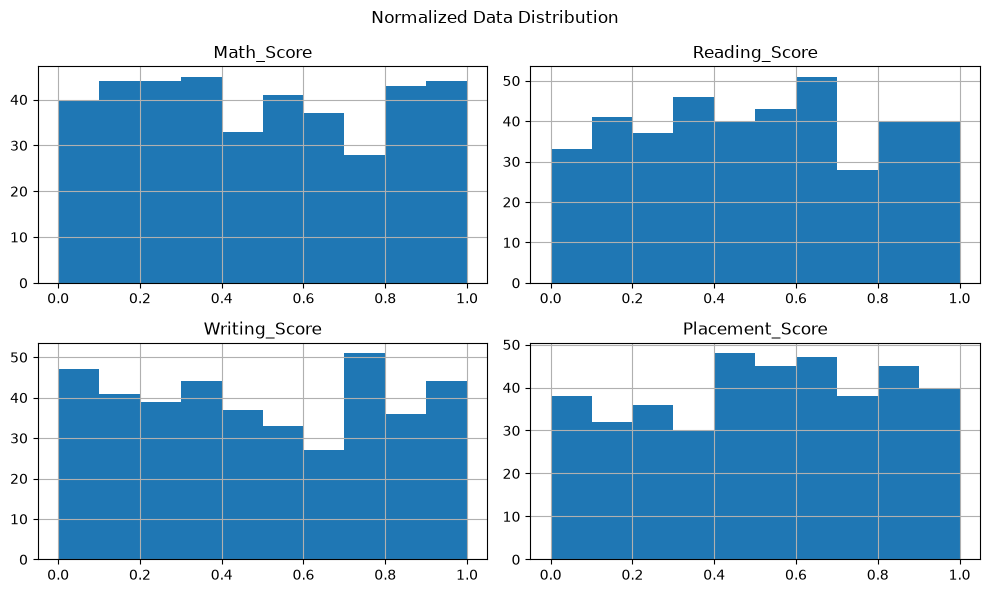

In [8]:
normalized_df.hist(figsize=(10, 6))

plt.suptitle("Normalized Data Distribution")
plt.tight_layout()
plt.show()

In [9]:


scaler = StandardScaler()

standardized_data = scaler.fit_transform(X)

standardized_df = pd.DataFrame(
    standardized_data,
    columns=features
)

standardized_df.head()

,Math_Score,Reading_Score,Writing_Score,Placement_Score
0,-1.196180,0.558888,-1.011972,-0.205094
1,-1.280519,0.470432,-0.679303,-0.030238
2,-0.268448,-0.237211,-0.180300,0.319473
3,0.068909,-0.325667,-0.346634,-0.467378
4,-1.364858,1.001165,-1.427808,0.844041


In [10]:
print("Mean:")
print(standardized_df.mean())

print("\nStandard Deviation:")
print(standardized_df.std())

Mean:
Math_Score         4.362982e-16
Reading_Score      7.123235e-17
Writing_Score     -4.452022e-17
Placement_Score    2.003410e-16
dtype: float64

Standard Deviation:
Math_Score         1.001255
Reading_Score      1.001255
Writing_Score      1.001255
Placement_Score    1.001255
dtype: float64


In [11]:
pca = PCA(n_components=2)

pca_data = pca.fit_transform(standardized_data)

pca_df = pd.DataFrame(
    pca_data,
    columns=['PC1', 'PC2']
)

pca_df.head()

,PC1,PC2
0,-1.624426,-0.377492
1,-1.468524,-0.209915
2,-0.225731,-0.019917
3,0.029893,-0.627110
4,-2.283457,0.463899


In [12]:
print("Explained Variance Ratio:")

print(pca.explained_variance_ratio_)

print("\nTotal Variance:")
print(sum(pca.explained_variance_ratio_))

Explained Variance Ratio:
[0.28829677 0.27180147]

Total Variance:
0.5600982409826228


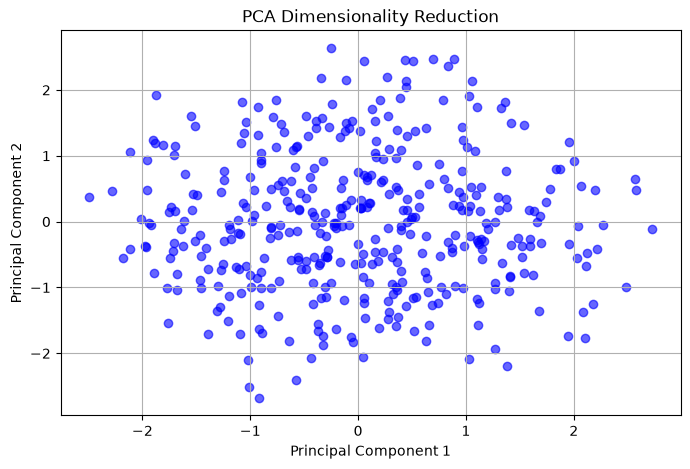

In [13]:
plt.figure(figsize=(8, 5))

plt.scatter(
    pca_df['PC1'],
    pca_df['PC2'],
    color='blue',
    alpha=0.6
)

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")

plt.title("PCA Dimensionality Reduction")

plt.grid()
plt.show()

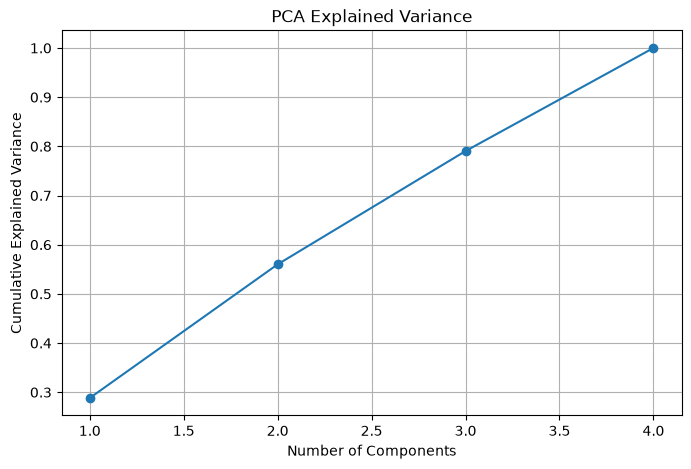

In [14]:
pca_full = PCA()

pca_full.fit(standardized_data)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    np.cumsum(pca_full.explained_variance_ratio_),
    marker='o'
)

plt.xlabel("Number of Components")
plt.ylabel("Cumulative Explained Variance")

plt.title("PCA Explained Variance")

plt.grid()
plt.show()

In [15]:
print("Original Shape:", X.shape)

print("Normalized Shape:", normalized_df.shape)

print("Standardized Shape:", standardized_df.shape)

print("PCA Shape:", pca_df.shape)

Original Shape: (399, 4)
Normalized Shape: (399, 4)
Standardized Shape: (399, 4)
PCA Shape: (399, 2)


In [16]:
club_encoded = pd.get_dummies(
    df['Club_Join_Date'],
    prefix='Club_Year',
    dtype=int
)

club_encoded.head()

,Club_Year_2018,Club_Year_2019,Club_Year_2020,Club_Year_2021
0,0,0,0,1
1,0,1,0,0
2,0,0,0,1
3,0,0,0,1
4,0,1,0,0
